# EN3160 Assignment 03: Neural Networks

**Name:** [Perera H.A.J.I]

**Student ID / Index number:** [230477X]

**Date:** [19-10-2026]

## Task 1: Fully Connected Neural Network with Manual Backpropagation

Using GPU: NVIDIA GeForce RTX 4060 Laptop GPU
PyTorch CUDA version: 12.6


100%|██████████| 170M/170M [59:02<00:00, 48.1kB/s]   


Epoch 1/10, Loss: 1.8078
Epoch 2/10, Loss: 1.6768
Epoch 3/10, Loss: 1.6158
Epoch 4/10, Loss: 1.5710
Epoch 5/10, Loss: 1.5309
Epoch 6/10, Loss: 1.4962
Epoch 7/10, Loss: 1.4673
Epoch 8/10, Loss: 1.4402
Epoch 9/10, Loss: 1.4167
Epoch 10/10, Loss: 1.3957


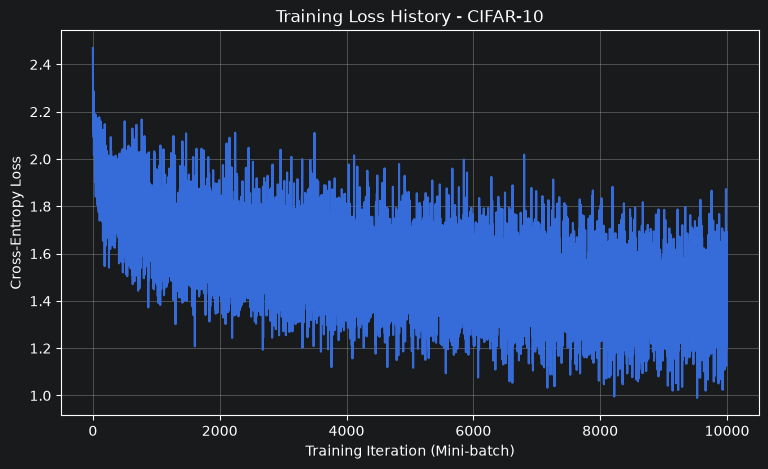

Training accuracy: 53.70%
Test accuracy: 47.93%


In [6]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
# Reproducibility
torch.manual_seed(42)
# GPU configuration
assert torch.cuda.is_available(), "CUDA is not available!"
device = torch.device("cuda:0")
print("Using GPU:", torch.cuda.get_device_name(0))
print("PyTorch CUDA version:", torch.version.cuda)
# 1. Dataloading
transform = transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.5, 0.5, 0.5),(0.5, 0.5, 0.5))])
batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data',train=True,download=True,transform=transform)
trainloader = torch.utils.data.DataLoader(trainset,batch_size=batch_size,shuffle=True,num_workers=0,pin_memory=True)
testset = torchvision.datasets.CIFAR10(root='./data',train=False,download=True,transform=transform)
testloader = torch.utils.data.DataLoader(testset,batch_size=batch_size,shuffle=False,num_workers=0,pin_memory=True)
classes = ('plane', 'car', 'bird', 'cat', 'deer','dog', 'frog', 'horse', 'ship', 'truck')
# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size
H = 100            # Hidden layer size
K = 10             # Output size
# Initialize weights and biases
# Input -> Hidden layer
w1 = torch.randn(Din, H, device=device) * (1 / Din)**0.5
b1 = torch.zeros(H, device=device)
# Hidden -> Output layer
w2 = torch.randn(H, K, device=device) * (1 / H)**0.5
b2 = torch.zeros(K, device=device)
# Hyperparameters
iterations = 10
lr = 0.1
lr_decay = 0.9
reg = 0
loss_history = []
# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        Ntr = inputs.shape[0]
        # Flatten inputs
        x_train = inputs.view(Ntr, -1)
        # One-hot encoding
        y_train_onehot = nn.functional.one_hot(labels, K).float()
        # Forward pass - Hidden layer
        z1 = x_train.mm(w1) + b1
        h = torch.sigmoid(z1)
        # Forward pass - Output layer
        y_pred = h.mm(w2) + b2
        # Softmax and Cross-Entropy Loss
        log_probs = y_pred - torch.logsumexp(y_pred, dim=1, keepdim=True)
        probs = torch.exp(log_probs)
        loss = -(1 / Ntr) * torch.sum(y_train_onehot * log_probs) + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()
        # Backpropagation - Output layer
        dy_pred = (probs - y_train_onehot) / Ntr
        dw2 = h.t().mm(dy_pred) + 2 * reg * w2
        db2 = dy_pred.sum(dim=0)
        # Backpropagation - Hidden layer
        dh = dy_pred.mm(w2.t())
        dz1 = dh * h * (1 - h)
        dw1 = x_train.t().mm(dz1) + 2 * reg * w1
        db1 = dz1.sum(dim=0)
        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2
    # Print loss for every epoch
    print(
        f"Epoch {t + 1}/{iterations}, "
        f"Loss: {running_loss / len(trainloader):.4f}"
    )
    # Learning rate decay
    lr *= lr_decay
# 4. Plotting the Loss History
plt.figure(figsize=(9, 5))
plt.plot(loss_history)
plt.title("Training Loss History - CIFAR-10")
plt.xlabel("Training Iteration (Mini-batch)")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True)
plt.show()
# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        # Forward pass - Hidden layer
        h = torch.sigmoid(x_train.mm(w1) + b1)
        # Forward pass - Output layer
        y_train_pred = h.mm(w2) + b2
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()
train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")
# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        # Forward pass - Hidden layer
        h = torch.sigmoid(x_test.mm(w1) + b1)
        # Forward pass - Output layer
        y_test_pred = h.mm(w2) + b2
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()
test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

### Task 1 – Results and Discussion
A fully connected neural network consisting of 100 hidden neurons with sigmoid activation was implemented for CIFAR-10 classification. The network was trained for 10 epochs using cross entropy loss and manually implemented backpropagation. The training loss decreased consistently from **1.8078 in the first epoch to 1.3957 in the final epoch** indicating that the network successfully learned useful patterns from the training data. Although the mini batch loss fluctuated during training, the average loss decreased steadily across epochs. The model achieved a **training accuracy of 53.70% and a test accuracy of 47.93%**. The difference of 5.77 percentage points suggests a moderate generalization gap with slightly lower performance on unseen images. The relatively limited classification accuracy can be attributed partly to the fully connected architecture. Flattening the images removes their explicit two dimensional spatial arrangement preventing the network from directly exploiting local image features in the way convolutional neural networks can. Overall, the results demonstrate successful implementation of a two layer neural network with sigmoid activation, cross entropy loss and manual backpropagation. The experiment also highlights the limitations of shallow fully connected networks for image classification tasks.

## Task 2: LeNet-5 vs Modern CNN on MNIST

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Preprocessing
mnist_transform = transforms.Compose([transforms.Pad(2),transforms.ToTensor(),transforms.Normalize((0.1307,), (0.3081,))])
batch_size = 128
mnist_trainset = torchvision.datasets.MNIST(root="./data",train=True,download=True,transform=mnist_transform)
mnist_testset = torchvision.datasets.MNIST(root="./data",train=False,download=True,transform=mnist_transform)
mnist_trainloader = torch.utils.data.DataLoader(mnist_trainset,batch_size=batch_size,shuffle=True,num_workers=0,pin_memory=True)
mnist_testloader = torch.utils.data.DataLoader(mnist_testset,batch_size=batch_size,shuffle=False,num_workers=0,pin_memory=True)
print("Device:", device)
print("Training images:", len(mnist_trainset))
print("Test images:", len(mnist_testset))

100%|██████████| 9.91M/9.91M [00:20<00:00, 485kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 83.9kB/s]
100%|██████████| 1.65M/1.65M [00:03<00:00, 543kB/s]
100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]

Device: cuda
Training images: 60000
Test images: 10000


In [8]:
# Task 2(a) - LeNet-5
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Conv2d(6, 16, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Conv2d(16, 120, kernel_size=5),
            nn.Tanh()
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10)
        )
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x
lenet5 = LeNet5().to(device)
print(lenet5)

LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
    (7): Tanh()
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=120, out_features=84, bias=True)
    (2): Tanh()
    (3): Linear(in_features=84, out_features=10, bias=True)
  )
)


In [9]:
# Task 2(b) - Modern CNN
class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            # Convolution Block 1
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # Convolution Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # Convolution Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.25)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x
modern_cnn = ModernCNN().to(device)
print(modern_cnn)

ModernCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Dropout2d(p=0.25, inplace=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in

In [11]:
# Verify model outputs
dummy_input = torch.randn(4, 1, 32, 32, device=device)
lenet5.eval()
modern_cnn.eval()
with torch.no_grad():
    lenet_output = lenet5(dummy_input)
    modern_output = modern_cnn(dummy_input)
print("LeNet-5 output:", lenet_output.shape)
print("Modern CNN output:", modern_output.shape)
print("LeNet-5 parameters:",sum(p.numel() for p in lenet5.parameters()))
print("Modern CNN parameters:",sum(p.numel() for p in modern_cnn.parameters()))

LeNet-5 output: torch.Size([4, 10])
Modern CNN output: torch.Size([4, 10])
LeNet-5 parameters: 61706
Modern CNN parameters: 356682


In [12]:
# Task 2(c) - Training and Evaluation Functions
def evaluate_model(model, dataloader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.inference_mode():
        for inputs, labels in dataloader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * labels.size(0)
            predicted = torch.argmax(outputs, dim=1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    epoch_loss = running_loss / total
    epoch_acc = 100 * correct / total
    return epoch_loss, epoch_acc
def train_model(model, trainloader, testloader,epochs=10, lr=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [],"train_acc": [],"test_loss": [],"test_acc": []}
    for epoch in range(epochs):
        model.train()
        for inputs, labels in trainloader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            # Forward pass
            optimizer.zero_grad(set_to_none=True)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            # Backpropagation
            loss.backward()
            optimizer.step()
        # Evaluate after each epoch
        train_loss, train_acc = evaluate_model(model, trainloader, criterion)
        test_loss, test_acc = evaluate_model(model, testloader, criterion)
        # Record history
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)
        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Acc: {test_acc:.2f}%"
        )
    return history

In [13]:
# Task 2(a) - Train LeNet-5
print("Training LeNet-5")
lenet_history = train_model(lenet5,mnist_trainloader,mnist_testloader,epochs=10,lr=0.001)

Training LeNet-5
Epoch 01/10 | Train Loss: 0.1000 | Train Acc: 97.00% | Test Loss: 0.0965 | Test Acc: 97.10%
Epoch 02/10 | Train Loss: 0.0559 | Train Acc: 98.31% | Test Loss: 0.0595 | Test Acc: 98.34%
Epoch 03/10 | Train Loss: 0.0444 | Train Acc: 98.64% | Test Loss: 0.0515 | Test Acc: 98.35%
Epoch 04/10 | Train Loss: 0.0314 | Train Acc: 99.05% | Test Loss: 0.0427 | Test Acc: 98.61%
Epoch 05/10 | Train Loss: 0.0255 | Train Acc: 99.25% | Test Loss: 0.0407 | Test Acc: 98.77%
Epoch 06/10 | Train Loss: 0.0279 | Train Acc: 99.10% | Test Loss: 0.0468 | Test Acc: 98.71%
Epoch 07/10 | Train Loss: 0.0213 | Train Acc: 99.36% | Test Loss: 0.0411 | Test Acc: 98.71%
Epoch 08/10 | Train Loss: 0.0164 | Train Acc: 99.48% | Test Loss: 0.0396 | Test Acc: 98.79%
Epoch 09/10 | Train Loss: 0.0124 | Train Acc: 99.64% | Test Loss: 0.0372 | Test Acc: 98.91%
Epoch 10/10 | Train Loss: 0.0109 | Train Acc: 99.69% | Test Loss: 0.0367 | Test Acc: 98.89%


In [14]:
# Task 2(b) - Train Modern CNN
print("Training Modern CNN")
modern_history = train_model(modern_cnn,mnist_trainloader,mnist_testloader,epochs=10,lr=0.001)

Training Modern CNN
Epoch 01/10 | Train Loss: 0.0412 | Train Acc: 98.74% | Test Loss: 0.0383 | Test Acc: 98.74%
Epoch 02/10 | Train Loss: 0.0358 | Train Acc: 98.95% | Test Loss: 0.0365 | Test Acc: 98.85%
Epoch 03/10 | Train Loss: 0.0236 | Train Acc: 99.25% | Test Loss: 0.0270 | Test Acc: 99.05%
Epoch 04/10 | Train Loss: 0.0191 | Train Acc: 99.40% | Test Loss: 0.0251 | Test Acc: 99.23%
Epoch 05/10 | Train Loss: 0.0156 | Train Acc: 99.51% | Test Loss: 0.0228 | Test Acc: 99.31%
Epoch 06/10 | Train Loss: 0.0131 | Train Acc: 99.59% | Test Loss: 0.0228 | Test Acc: 99.31%
Epoch 07/10 | Train Loss: 0.0150 | Train Acc: 99.50% | Test Loss: 0.0257 | Test Acc: 99.10%
Epoch 08/10 | Train Loss: 0.0130 | Train Acc: 99.55% | Test Loss: 0.0259 | Test Acc: 99.20%
Epoch 09/10 | Train Loss: 0.0076 | Train Acc: 99.78% | Test Loss: 0.0237 | Test Acc: 99.33%
Epoch 10/10 | Train Loss: 0.0094 | Train Acc: 99.66% | Test Loss: 0.0269 | Test Acc: 99.11%


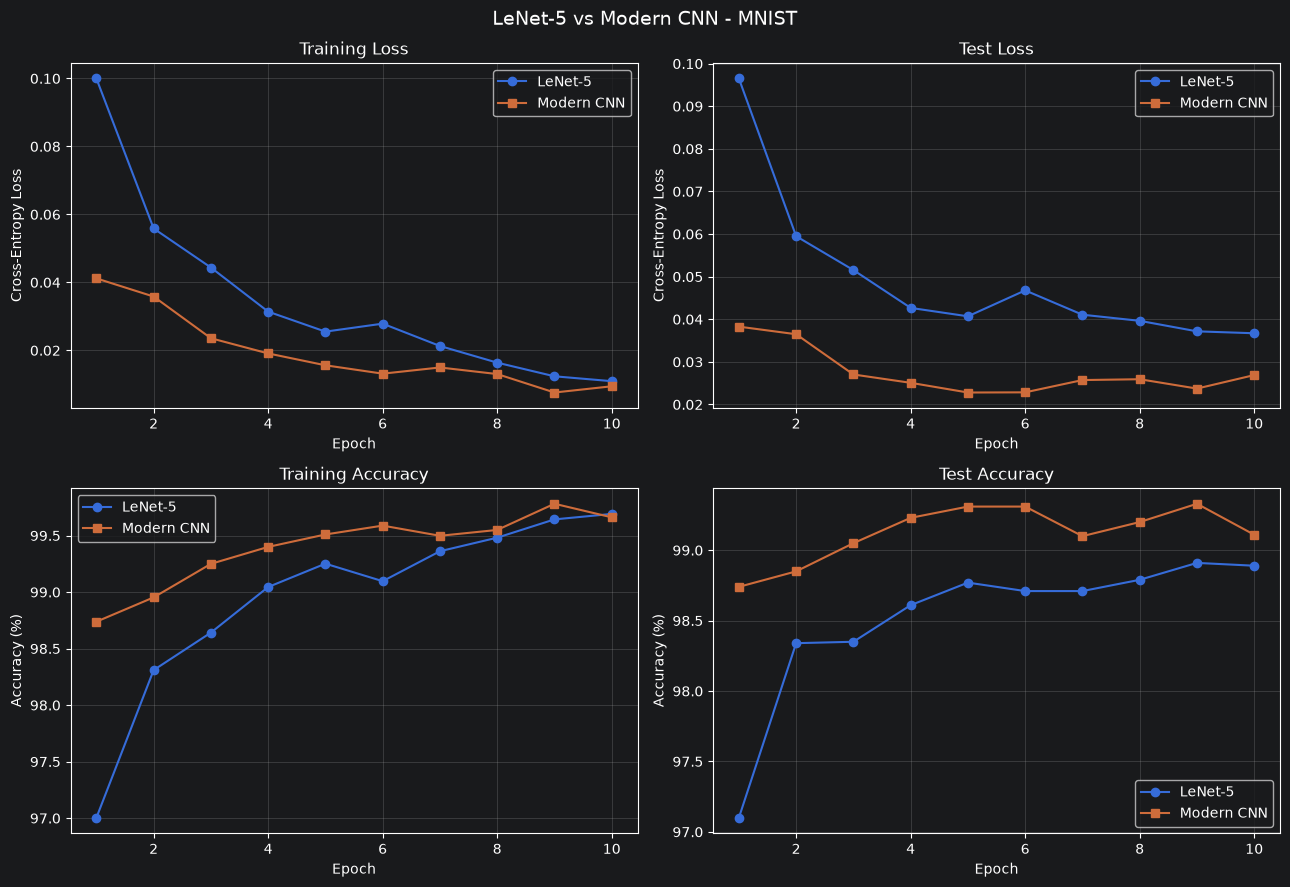

In [15]:
# Task 2(c) - Training Curves Comparison
epochs = range(1, 11)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
metrics = [("train_loss", "Training Loss", "Cross-Entropy Loss"),("test_loss", "Test Loss", "Cross-Entropy Loss"),("train_acc", "Training Accuracy", "Accuracy (%)"),("test_acc", "Test Accuracy", "Accuracy (%)")]
for ax, (metric, title, ylabel) in zip(axes.flat, metrics):
    ax.plot(epochs, lenet_history[metric],marker="o", label="LeNet-5")
    ax.plot(epochs, modern_history[metric],marker="s", label="Modern CNN")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.suptitle("LeNet-5 vs Modern CNN - MNIST",fontsize=14)
plt.tight_layout()
plt.show()

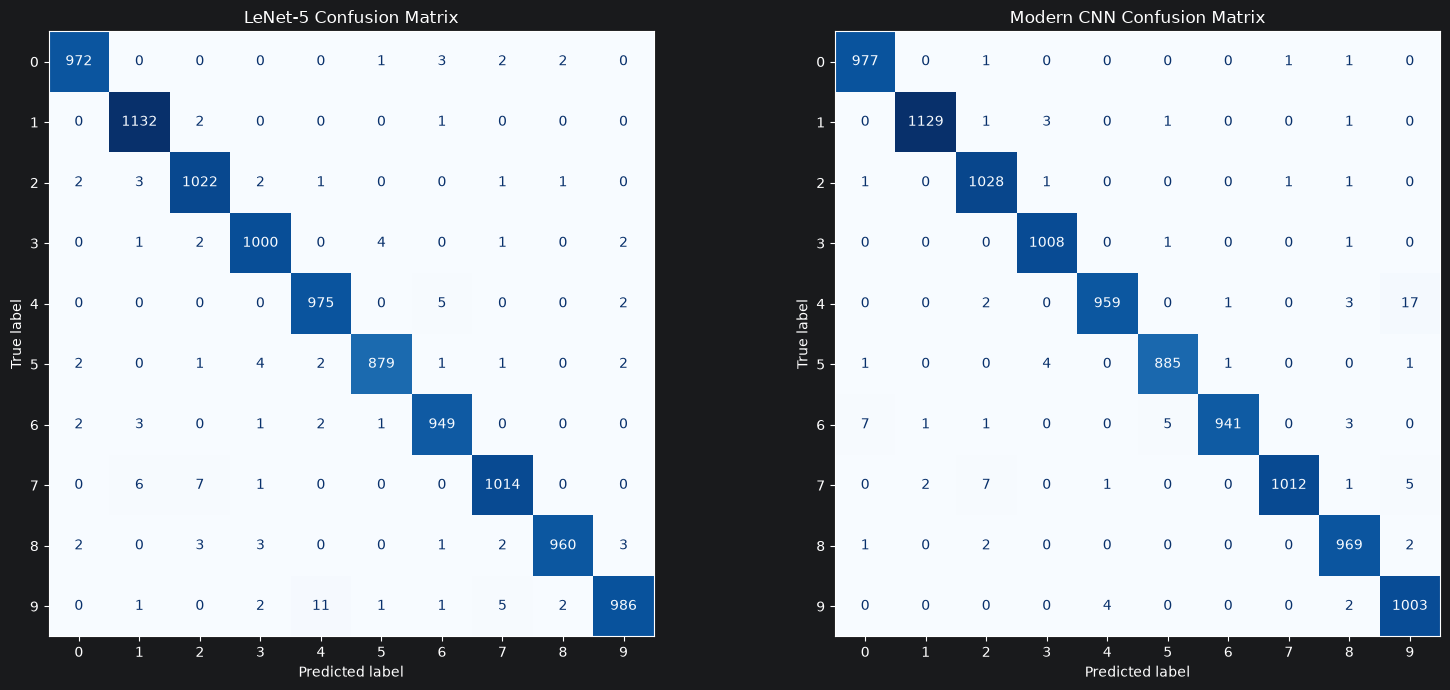

In [16]:
# Task 2(c) - Confusion Matrices
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
def get_predictions(model, dataloader):
    model.eval()
    all_labels = []
    all_predictions = []
    with torch.inference_mode():
        for inputs, labels in dataloader:
            inputs = inputs.to(device, non_blocking=True)
            outputs = model(inputs)
            predicted = torch.argmax(outputs, dim=1)
            all_predictions.extend(predicted.cpu().tolist())
            all_labels.extend(labels.tolist())
    return all_labels, all_predictions
# Predictions from both models
lenet_true, lenet_pred = get_predictions(lenet5, mnist_testloader)
modern_true, modern_pred = get_predictions(modern_cnn, mnist_testloader)
# Confusion matrices
cm_lenet = confusion_matrix(lenet_true, lenet_pred, labels=range(10))
cm_modern = confusion_matrix(modern_true, modern_pred, labels=range(10))
# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
ConfusionMatrixDisplay(confusion_matrix=cm_lenet,display_labels=range(10)).plot(ax=axes[0],cmap="Blues",colorbar=False,values_format="d")
axes[0].set_title("LeNet-5 Confusion Matrix")
ConfusionMatrixDisplay(confusion_matrix=cm_modern,display_labels=range(10)).plot(ax=axes[1],cmap="Blues",colorbar=False,values_format="d")
axes[1].set_title("Modern CNN Confusion Matrix")
plt.tight_layout()
plt.show()

### Task 2 – Results and Discussion
LeNet-5 and a modern three layer convolutional neural network incorporating batch normalization and dropout were trained on MNIST for 10 epochs under identical training conditions. Both networks used the Adam optimizer with a learning rate of 0.001 and cross entropy loss.

**Training Performance**
Both models demonstrated effective learning, with their training losses decreasing considerably over the 10 epochs. LeNet 5 achieved a final training accuracy of 99.69%, while the modern CNN achieved 99.66%.

**Test Performance**
The modern CNN achieved a final test accuracy of 99.11% outperforming LeNet 5 which achieved 98.89%. The modern CNN also recorded a lower final test loss of 0.0269 compared with 0.0367 for LeNet 5 indicating better predictive performance on the test set.

**Generalization and Overfitting**
The generalization gaps were relatively small measuring 0.80 percentage points for LeNet-5 and 0.55 percentage points for the modern CNN. Both networks demonstrated minor fluctuations in test performance toward the end of training suggesting some overfitting. The modern CNN achieved its highest test accuracy of 99.33% in epoch 9 before declining to 99.11% in the final epoch.

**Architectural Comparison**
LeNet-5 contains 61,706 parameters whereas the modern CNN contains 356,682 parameters. The modern CNN benefits from a more contemporary architecture incorporating ReLU activations, batch normalization, max pooling and dropout. These features, together with its greater capacity may contribute to its improved test performance. However the results do not isolate the effect of any individual architectural component.

**Conclusion**
Both architectures demonstrated strong classification performance on MNIST. The modern CNN achieved slightly higher test accuracy and lower test loss while LeNet-5 provided competitive performance with substantially fewer parameters. This illustrates the trade off between model complexity and predictive performance.

## Task 3: ResNet-18 Transfer Learning

[Add your implementation, experiments, results, and discussion here.]